In [19]:
import torch
from matplotlib import pyplot

import importlib
import velocity_model
import estimate_velocity
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

L = 5e6
v0 = 1e2
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
h_tgrid = torch.linspace(0, 3600, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
mtrue.h_log = torch.nn.Parameter(torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double)))
mtrue.g_log = torch.nn.Parameter(torch.log(torch.tensor([10, 0.1], dtype=torch.double)))

In [31]:
coverage = 1e4
x = torch.linspace(0, L, steps=1000)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
m.h_sigma = 2
m.h_log = torch.nn.Parameter(mtrue.h_log.clone())
m.g_log = torch.nn.Parameter(mtrue.g_log.clone())
y_obs = torch.poisson(m.P(x) * coverage)
s_obs = torch.sqrt(y_obs)

torch.autograd.set_detect_anomaly(True)
l = velocity_model.VelocityModelLoss(x, y_obs.detach(), s_obs.detach(), m)
fit = estimate_velocity.FitModel(m, l)
print(fit.loss())
fit.optimize()
print(fit.loss())

tensor([505.2066], dtype=torch.float64, grad_fn=<AddBackward0>)
tensor([499.8298], dtype=torch.float64, grad_fn=<AddBackward0>)


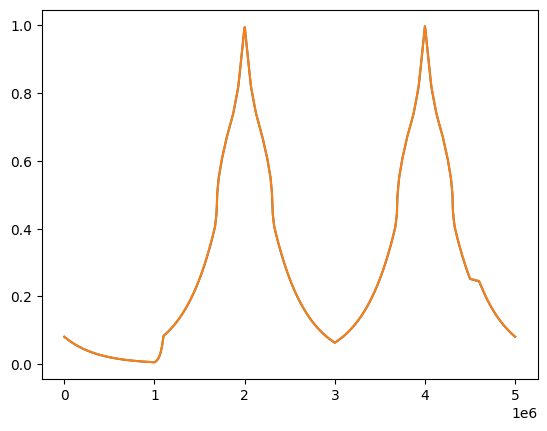

In [33]:
p = m.P(x).detach().numpy()
ptrue = mtrue.P(x).detach().numpy()
pyplot.plot(x, p, label="est")
pyplot.plot(x, ptrue, label="true")